# TenantEase Khata: late-payment risk model walkthrough

This notebook reproduces the risk model end to end on a free Colab runtime
with no API key. It imports the same modules the FastAPI backend uses, so the
notebook and the app cannot drift apart. Every tenant and payment row is
synthetic (Faker `en_IN`, seed 42); the metrics show the pipeline works under
known conditions and are not production accuracy.


## 1. Install the repository

Clone the public repo and install the backend in editable mode. An editable
install is what lets the cells below `import app.ml...` and reuse the exact
training, feature and evaluation code the server ships, instead of a copy.
Nothing here needs a GPU or an API key.


In [1]:
!git clone https://github.com/agniv-dutta/TenantEase.git repo
%cd repo
!pip -q install -e 'backend[dev]'

import sys, subprocess
print('python', sys.version.split()[0])
subprocess.run([sys.executable, '-c', 'import lightgbm, shap, sklearn; print("lightgbm", lightgbm.__version__, "| shap", shap.__version__, "| sklearn", sklearn.__version__)'])


(Not executed here so the local repo is reused. On Colab this cell
clones the repo and runs pip install -e 'backend[dev]'.)


## 2. The problem, and the as-of design

A property manager wants to know which leases are likely to pay rent more
than five days late next cycle, so reminders can be scheduled earlier or a
few tenants can be followed up personally. The score only nudges reminders;
it is never used for eviction, pricing or screening.

Each training row is one (lease, cycle) pair. Its features are computed at an
**as-of instant** = the cycle's due date minus seven days, never later than the
demo clock `DEMO_TODAY`. The label is what actually happened after the due date.
The diagram below draws one row's timeline: features may only see information
whose timestamp is at or before `as_of`; the label lives to the right of it.


Demo clock DEMO_TODAY: 2026-10-19
Open cycle: 2026-10-01


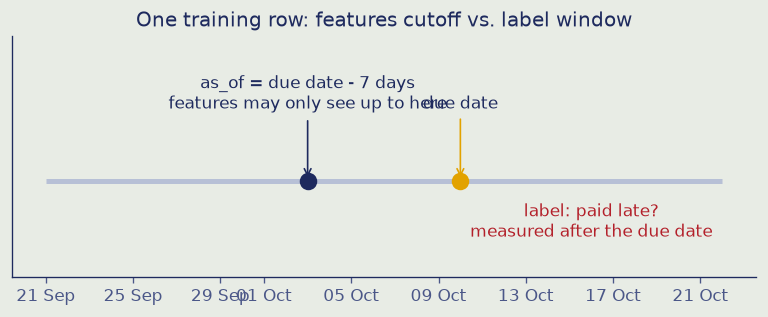

In [5]:
from app.ml import report_assets as ra
from app import clock

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import timedelta

ra._setup_style()  # Khata palette from app/ml/report_assets.py

due = clock.open_cycle().replace(day=10)
as_of = due - timedelta(days=7)

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.hlines(0, as_of - timedelta(days=12), due + timedelta(days=12), color=ra.RULE, linewidth=3)
ax.scatter([as_of], [0], color=ra.INDIGO, zorder=3, s=90)
ax.scatter([due], [0], color=ra.HALDI, zorder=3, s=90)
ax.annotate('as_of = due date - 7 days\nfeatures may only see up to here',
            xy=(as_of, 0), xytext=(as_of, 0.45), ha='center', color=ra.INDIGO,
            arrowprops=dict(arrowstyle='->', color=ra.INDIGO))
ax.annotate('due date', xy=(due, 0), xytext=(due, 0.45), ha='center',
            color=ra.INDIGO, arrowprops=dict(arrowstyle='->', color=ra.HALDI))
ax.annotate('label: paid late?\nmeasured after the due date',
            xy=(due + timedelta(days=6), -0.35), ha='center', color=ra.STAMP_RED)
ax.axvspan(as_of, due + timedelta(days=12), color=ra.CHUNA, alpha=0.6, zorder=0)
ax.set_yticks([])
ax.set_ylim(-0.6, 0.9)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.set_title('One training row: features cutoff vs. label window')
ra._clean(ax)
plt.show()

print('Demo clock DEMO_TODAY:', clock.today().isoformat())
print('Open cycle:', clock.open_cycle().isoformat())


## 3. Generate the synthetic data (seed 42)

`app.ml.synth.write_db` builds the whole portfolio and lays the calendar out
around `DEMO_TODAY`, so `make seed` is reproducible for a given seed. The
planted effects are documented in `docs/synthetic_data.md`; the table below is
read straight from that file so it cannot drift.


In [7]:
import re
from pathlib import Path
from app.ml.synth import write_db

# The configured database path is absolute (backend/data/khata.db), so the
# same file is used no matter which directory the notebook runs from.
stats = write_db('backend/data/khata.db', seed=42)
for k, v in stats.items():
    print(f'{k}: {v}')

doc = Path('docs/synthetic_data.md').read_text(encoding='utf-8')
effects = re.search(r'Planted effects and their \*\*direction\*\*:(.*?)The intercept', doc, re.S).group(1).strip()
print()
print(effects)


properties: 6
units: 140
tenants: 155
leases: 155
payments: 3236
closed_cycles: 24
demo_today: 2026-10-19
base_rate: 0.1818
intercept: -2.0312

| Effect | Definition | Direction on late risk |
|---|---|---|
| reliability z | hidden per-tenant | higher z lowers risk |
| autocorrelation | previous cycle was >5 days late | raises risk |
| festival month | cycle month in Oct, Nov (Diwali) or April | raises risk |
| recent rent hike | first 2 cycles after a hike | raises risk |
| cash share | share of cash payments in last 6 cycles | raises risk |
| short tenure | fewer than 4 months in the lease | raises risk |
| logistic noise | N(0, 0.8) per cycle | adds irreducible variance |


## 4. Build features and run the leakage test live

The feature pipeline in `app.ml.features` is the only place features are
built. `tests/test_features.py` recomputes every feature independently from
records with timestamps at or before `as_of` and asserts the pipeline matches,
and it checks that shuffling future payments cannot change an as-of feature.
We run that whole test file here and assert it passes.


In [9]:
from sqlmodel import Session, create_engine
from app.ml.features import build_training_frame, feature_columns

engine = create_engine('sqlite:///backend/data/khata.db', connect_args={'check_same_thread': False})
with Session(engine) as session:
    frame, _ = build_training_frame(session)

print('training rows:', len(frame), '| features:', len(feature_columns()))
excluded = {'name', 'phone', 'property', 'locality', 'preferred_language'} & set(feature_columns())
print('excluded identity columns present:', excluded or 'none')

import subprocess, sys
r = subprocess.run([sys.executable, '-m', 'pytest', 'backend/tests/test_features.py', '-q'],
                   capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])
assert r.returncode == 0, 'leakage test failed'
assert excluded == set()


training rows: 3236 | features: 26
excluded identity columns present: none
4 passed in 6.24s


## 5. Train B0, B1 and M with the temporal split

`app.ml.train` fits three models on a time split (train cycles 1-16, validate
17-20, test 21-24) and saves `metrics.json` via `app.ml.evaluate`, which also
runs `simulate`, `explain` and the LLM evals. B0 is the rule 'late last cycle
implies late this cycle', B1 is logistic regression, and M is LightGBM with a
calibrator chosen on the validation set. The comparison table below is read
from the saved artifacts and includes bootstrap intervals.


In [11]:
import json
from pathlib import Path

# Editable install makes `app` importable and the DB path is absolute, so
# these run from the repo root without changing directory.
!python -m app.ml.train
!python -m app.ml.evaluate
!python -m app.ml.simulate
!python -m app.llm.eval
!python -m app.llm.triage_eval

metrics = json.loads(Path('backend/app/ml/artifacts/metrics.json').read_text(encoding='utf-8'))
print(metrics['note'])
print(f"test rows {metrics['n_test_rows']} | base rate {metrics['test_base_rate']:.3f} | threshold {metrics['operating_threshold']:.3f}")

order = ['B0_rule_baseline', 'B1_logistic', 'M_lgbm_raw', 'M_lgbm_isotonic', 'M_lgbm_sigmoid', 'M_lgbm_smoothed', 'M_lgbm_shipped']
print(f"{'model':28} {'PR-AUC (95% CI)':28} {'ROC-AUC':8} {'Brier':6} {'ECE':6}")
for key in order:
    m = metrics['models'][key]
    ci = f"[{m['pr_auc_ci'][0]:.2f},{m['pr_auc_ci'][1]:.2f}]"
    print(f"{key:28} {m['pr_auc']:.3f} {ci:20} {m['roc_auc']:.3f}  {m['brier']:.3f}  {m['ece']:.3f}")

print()
print('paired lease-bootstrap differences (estimate, 95% CI):')
for name, diffs in metrics['paired_comparisons'].items():
    d = diffs['pr_auc']
    print(f"  {name}: PR-AUC {d['estimate']:+.3f} [{d['ci95'][0]:+.3f}, {d['ci95'][1]:+.3f}]")


$ python -m app.ml.train
{
  "n_rows": 3081,
  "n_test": 528,
  "test_base_rate": 0.16666666666666666,
  "pr_auc_m": 0.3180204366849039,
  "pr_auc_b0": 0.27540491118077326,
  "threshold": 0.2,
  "best_iteration": 39,
  "shipped_calibrator": "isotonic",
  "beats_baseline": true
}
$ python -m app.ml.evaluate
Wrote metrics, slices, shap, simulation and model card. Test PR-AUC M=0.318
$ python -m app.ml.simulate
Wrote C:\Users\Agniv Dutta\TenantEase\backend\app\ml\artifacts\simulation.json
$ python -m app.llm.eval
{
  "n_drafts": 90,
  "provider": "none (template path)",
  "sources": {
    "template": 90
  },
  "fallback_rate": 0.0,
  "guardrails": {
    "contains_amount": {
      "pass_rate": 1.0,
      "passed": 90,
      "failed": 0
    },
    "contains_due_date": {
      "pass_rate": 1.0,
      "passed": 90,
      "failed": 0
    },
    "pay_link_once": {
      "pass_rate": 1.0,
      "passed": 90,
      "failed": 0
    },
    "length": {
      "pass_rate": 1.0,
      "passed": 90,
   

## 6. Calibration, and the ranking-ties issue

Raw boosted scores are not probabilities, so `app.ml.evaluate` compares raw
scores against isotonic and sigmoid (Platt) calibration on the validation set
and ships the lowest-Brier option. Calibration changes the numbers shown to
managers, not the order of leases. The second issue is ties: many rows score
identically on the rule baseline, so ranking has to break ties deterministically
(here by last cycle's outstanding days, then lease id, as in `app.ml.simulate`).
The chart shows reliability before and after calibration.


b0: 20 top picks, 1 distinct score values (ties matter for ranking)
b1: 20 top picks, 20 distinct score values (ties matter for ranking)
m: 20 top picks, 3 distinct score values (ties matter for ranking)


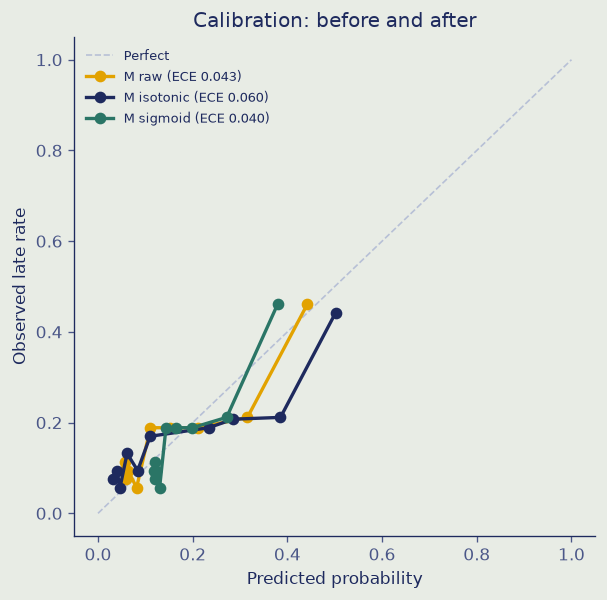

In [13]:
import joblib
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5.6, 5.4))
ax.plot([0, 1], [0, 1], color=ra.RULE, linestyle='--', linewidth=1, label='Perfect')
for key, color, label in [
    ('M_lgbm_raw', ra.HALDI, f"M raw (ECE {metrics['models']['M_lgbm_raw']['ece']:.3f})"),
    ('M_lgbm_isotonic', ra.INDIGO, f"M isotonic (ECE {metrics['models']['M_lgbm_isotonic']['ece']:.3f})"),
    ('M_lgbm_sigmoid', ra.VERDIGRIS, f"M sigmoid (ECE {metrics['models']['M_lgbm_sigmoid']['ece']:.3f})"),
]:
    curve = metrics['models'][key]['calibration_curve']
    ax.plot([c['mean_predicted'] for c in curve], [c['fraction_positive'] for c in curve],
            marker='o', color=color, linewidth=2, label=label)
ax.set_xlabel('Predicted probability')
ax.set_ylabel('Observed late rate')
ax.set_title('Calibration: before and after')
ax.legend(frameon=False, fontsize=8)
ra._clean(ax)
plt.show()

preds = joblib.load('backend/app/ml/artifacts/test_predictions.joblib')
test = preds[preds['split'] == 'test']
for col in ('b0', 'b1', 'm'):
    top = test.nlargest(20, col)[col]
    print(f"{col}: {len(top)} top picks, {top.nunique()} distinct score values (ties matter for ranking)")


## 7. SHAP summary and plain-language explanations

`app.ml.explain` runs a SHAP `TreeExplainer` over the LightGBM model and renders
each top feature through the same plain-language templates the API returns to
the drawer, using `render_feature_sentence`. The bar chart is the mean absolute
SHAP impact per feature across the scored open cycle; below it are three
example explanations in the exact wording a manager would see.


Lease 1:
  - Is a salaried tenant (lowers risk)
  - This cycle is in month 10 (raises risk)
  - Has been on time 19 months in a row (lowers risk)

Lease 2:
  - Is not a salaried tenant (raises risk)
  - Has been on time 24 months in a row (lowers risk)
  - This cycle falls in a festival month (raises risk)

Lease 3:
  - Is a salaried tenant (lowers risk)
  - This cycle is in month 10 (raises risk)
  - Has been on time 0 months in a row (raises risk)



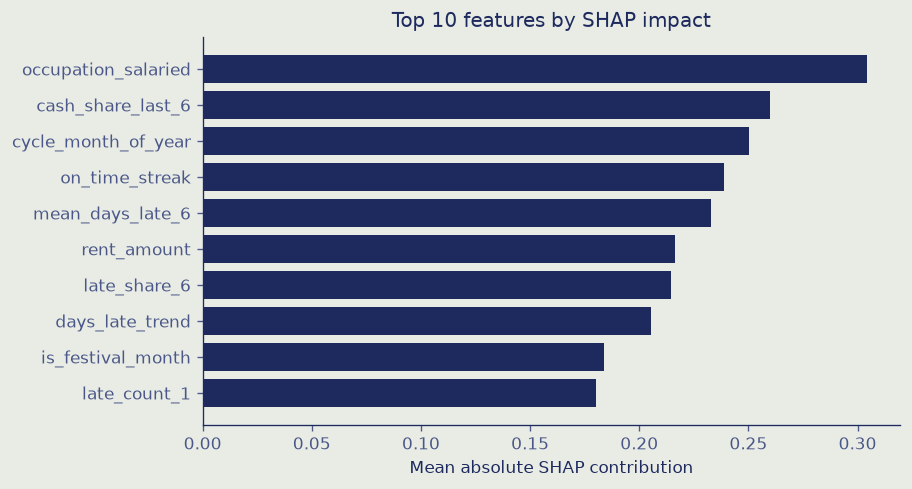

In [15]:
shap_art = json.loads(Path('backend/app/ml/artifacts/shap_top_features.json').read_text(encoding='utf-8'))
ranked = ra._shap_importance(shap_art)

import matplotlib.pyplot as plt
names = [r[0] for r in reversed(ranked)]
values = [r[1] for r in reversed(ranked)]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(names, values, color=ra.INDIGO)
ax.set_xlabel('Mean absolute SHAP contribution')
ax.set_title('Top 10 features by SHAP impact')
ra._clean(ax)
plt.show()

example_leases = list(shap_art['leases'].keys())[:3]
for lid in example_leases:
    print(f'Lease {lid}:')
    for factor in shap_art['leases'][lid]:
        print(f"  - {factor['sentence']} ({factor['direction']} risk)")
    print()


## 8. Slice audit by occupation, tenure and message language

Slice metrics come from `app.ml.evaluate.build_slices` at the operating
threshold. Occupation type is a feature behind a config flag, so it is audited
and ablated; tenure (established vs. cold-start) is audited for the same reason.
Preferred language is **not** a feature at all, so it is audited only. The gap
flags call out any pairwise recall or false-positive-rate gap above ten points.


In [17]:
slices = json.loads(Path('backend/app/ml/artifacts/slices.json').read_text(encoding='utf-8'))
for family, buckets in slices['slices'].items():
    print(family)
    for bucket, s in buckets.items():
        print(f"  {bucket:12} n={s['n']:4d}  late={s['late_rate']:.3f}  recall={s['recall']:.3f}  fpr={s['fpr']:.3f}")
    print()
print('gap flags above 10 points:', len(slices['gap_flags']))
for flag in slices['gap_flags'][:6]:
    print(f"  {flag['slice']} {flag['metric']}: {flag['a']} vs {flag['b']} = {flag['gap_pp']:.1f} points")

abl = metrics['ablation_no_occupation']
print()
print(f"occupation ablation: PR-AUC {abl['pr_auc']:.3f} without occupation vs {metrics['models']['M_lgbm_shipped']['pr_auc']:.3f} with")


occupation_type
  business     n= 120  late=0.158  recall=0.895  fpr=0.713
  gig          n=  76  late=0.355  recall=0.889  fpr=0.816
  salaried     n= 272  late=0.110  recall=0.133  fpr=0.050
  student      n=  60  late=0.200  recall=0.833  fpr=0.688

tenure_group
  cold_start   n=   8  late=0.125  recall=1.000  fpr=0.571
  established  n= 520  late=0.167  recall=0.621  fpr=0.353

rent_band
  10k_to_20k   n= 308  late=0.172  recall=0.566  fpr=0.361
  20k_plus     n= 140  late=0.171  recall=0.750  fpr=0.353
  under_10k    n=  80  late=0.138  recall=0.636  fpr=0.348

preferred_language_audit_only
  en           n= 204  late=0.176  recall=0.528  fpr=0.292
  hi           n= 112  late=0.170  recall=0.474  fpr=0.280
  hinglish     n= 212  late=0.156  recall=0.818  fpr=0.458

gap flags above 10 points: 16
  occupation_type recall: business vs salaried = 76.1 points
  occupation_type recall: gig vs salaried = 75.6 points
  occupation_type recall: salaried vs student = 70.0 points
  occupation

## 9. Follow-up simulation (assumption-based)

`app.ml.simulate` projects how many lates the model's top-N picks would avoid
for an assumed relative reduction in late probability per follow-up. **These
numbers are assumptions, not measurements.** The prototype never ran an A/B
test; the sweep exists to show the shape of the decision, so the table is
labelled accordingly and compares the model against the rule baseline.


In [19]:
sim = json.loads(Path('backend/app/ml/artifacts/simulation.json').read_text(encoding='utf-8'))
print(f"label: {sim['label']}")
print(sim['caveat'])
print()
header = 'follow-ups | ' + ' | '.join(f"{int(s*100)}% effect" for s in sim['effect_sweep'])
print(header)
print('-' * len(header))
for row in sim['rows']:
    cells_ = ' | '.join(f"{row['expected_late_avoided_model'][f'{s:.2f}']:.2f}" for s in sim['effect_sweep'])
    print(f"top {row['follow_up_per_cycle']:>2}     | {cells_}")


label: assumption-based, not measured
These are assumption-based projections with a swept nudge effect, not measured outcomes. Proving that nudges change behaviour needs a real A/B test.

follow-ups | 5% effect | 10% effect | 15% effect | 25% effect
-------------------------------------------------------------
top  5     | 0.57 | 1.13 | 1.70 | 2.83
top 10     | 1.03 | 2.06 | 3.08 | 5.14
top 15     | 1.49 | 2.98 | 4.47 | 7.45
top 20     | 1.89 | 3.79 | 5.68 | 9.47
top 30     | 2.57 | 5.15 | 7.72 | 12.87


## 10. The reminder planner, and a draft message

`app.api.reminders.build_plan` turns a risk tier into a deterministic schedule,
and `app.llm.drafter.draft_message` writes the text. With no provider configured
(the default, `LLM_PROVIDER=none`) drafting uses the vetted templates in
`app.llm.templates` and runs them through the guardrails. Below we plan for each
tier and draft three template messages in the three languages. The LLM path is
shown behind a flag that is off by default.


In [21]:
from datetime import date
from app.api.reminders import build_plan
from app.llm.drafter import draft_message
from app.llm.templates import render_template

due = date(2026, 11, 5)
for tier in ('low', 'medium', 'high'):
    steps = build_plan(tier, 'whatsapp', due, has_overdue=False)
    print(f'{tier} tier:')
    for s in steps:
        print(f"  {s.date.isoformat()}  {s.channel:8} {s.tone:11} owner={s.owner}")
    print()

print('template drafts (LLM_PROVIDER=none, the default):')
for language in ('en', 'hi', 'hinglish'):
    res = draft_message('Sunita Sharma', 'MAN-07', 16500, '5 Nov', language, 'friendly', False)
    print(f"  [{language}] source={res.source}")
    print(f"    {res.message}")

# The LLM path is opt-in only: set LLM_PROVIDER and an API key, then rerun.
import os
print()
print('LLM_PROVIDER =', os.environ.get('LLM_PROVIDER', 'none'), '(off by default; no key needed for this notebook)')


low tier:
  2026-11-04  whatsapp friendly    owner=system

medium tier:
  2026-11-02  whatsapp neutral     owner=system
  2026-11-05  whatsapp neutral     owner=system

high tier:
  2026-10-31  whatsapp friendly    owner=system
  2026-11-03  call     friendly    owner=manager

template drafts (LLM_PROVIDER=none, the default):
  [en] source=template
    Hi Sunita, just a friendly reminder that rent of Rs 16,500 is due on 5 Nov. You can pay here: {PAY_LINK}. Thank you!
  [hi] source=template
    नमस्ते Sunita, 5 Nov को 16,500 रुपये का किराया देय है। यहाँ भुगतान करें: {PAY_LINK}। धन्यवाद।
  [hinglish] source=template
    Namaste Sunita, 5 Nov ko 16,500 rupaye ka kiraya due hai. Yahan pay karein: {PAY_LINK}. Dhanyavaad.

LLM_PROVIDER = none (off by default; no key needed for this notebook)


## 11. Limitations, in plain words

- The data is synthetic with planted effects. A good score here shows the
  pipeline is wired correctly, not that it would work on real tenants.
- The test set is small, so the slice gaps and confidence intervals are noisy.
- Ranking uses raw scores while the displayed probability is calibrated; do not
  confuse the two.
- The follow-up simulation is assumption-based. It does not prove nudges change
  behaviour; only a real A/B test could.
- The model must never decide eviction, rent pricing or screening. It only
  chooses who gets an earlier or more personal reminder, and a human approves
  every reminder before it is sent.
- Occupation type can act as a proxy for protected characteristics, so it stays
  behind a config flag, is ablated in the report and is audited by slice.


In [23]:
print('Key numbers reproduced from backend/app/ml/artifacts/metrics.json')
print(f"  test rows: {metrics['n_test_rows']}")
print(f"  shipped model: {metrics['shipped_model_key']}")
print(f"  shipped PR-AUC: {metrics['models']['M_lgbm_shipped']['pr_auc']:.3f}")
print(f"  shipped ROC-AUC: {metrics['models']['M_lgbm_shipped']['roc_auc']:.3f}")
print(f"  test base rate: {metrics['test_base_rate']:.3f}")
print(f"  operating threshold: {metrics['operating_threshold']:.3f}")


Key numbers reproduced from backend/app/ml/artifacts/metrics.json
  test rows: 528
  shipped model: M_lgbm_isotonic
  shipped PR-AUC: 0.318
  shipped ROC-AUC: 0.688
  test base rate: 0.167
  operating threshold: 0.200
